# Task 0 — Quantization research
**Question:** How can quantization reduce the size of models such as BERT and LLaMA?

Quantization represents weights (and optionally activations) using fewer bits, reducing memory and often memory bandwidth. Theoretical raw weight memory for $N$ parameters and $b$ bits per parameter is $M=Nb/8$ bytes; actual model memory also includes scales, zero-points, activations, metadata, and possibly unquantized layers.

- **Post-training quantization (PTQ):** quantize a pretrained model without full retraining; calibration may be used.
- **Quantization-aware training (QAT):** simulate quantization during training so the model can adapt.
- **Weight-only quantization:** reduce weight storage; activations can remain higher precision.
- **Dynamic vs static quantization:** dynamic schemes determine some activation ranges at runtime, whereas static schemes use calibration ranges.
- **LLMs:** 8-bit and 4-bit weight loading can make large models more accessible; accuracy, latency, and hardware support must be evaluated. QLoRA combines 4-bit frozen base weights with trainable low-rank adapters; this is not equivalent to training all base weights in 4-bit.

**Trade-offs:** quantization can affect accuracy, numerical stability, runtime speed and device compatibility. Smaller size does not guarantee faster inference on every CPU/GPU.

**References:** Jacob et al., 2018 (https://arxiv.org/abs/1712.05877); Dettmers et al., QLoRA 2023 (https://arxiv.org/abs/2305.14314); PyTorch quantization docs (https://pytorch.org/docs/stable/quantization.html).

format  bits  theoretical_weight_memory_GB
  FP32    32                           4.0
  FP16    16                           2.0
  INT8     8                           1.0
  INT4     4                           0.5


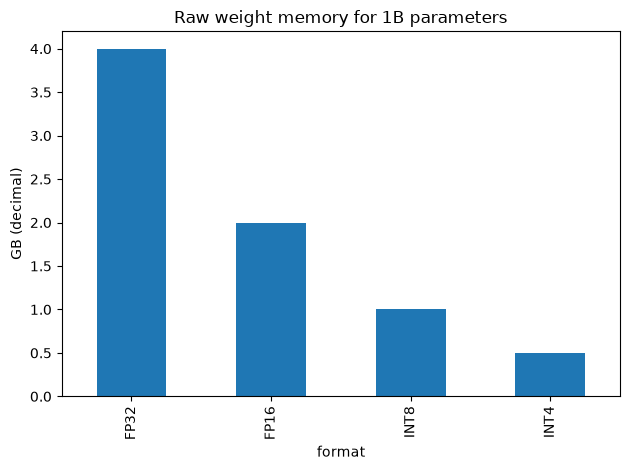

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
parameters=1_000_000_000
formats={'FP32':32,'FP16':16,'INT8':8,'INT4':4}
df=pd.DataFrame({'format':list(formats),'bits':list(formats.values())})
df['theoretical_weight_memory_GB']=parameters*df['bits']/8/1e9
print(df.to_string(index=False))
ax=df.plot.bar(x='format',y='theoretical_weight_memory_GB',legend=False,title='Raw weight memory for 1B parameters')
ax.set_ylabel('GB (decimal)')
plt.tight_layout();plt.show()

## Code example: toy symmetric INT8 weight quantization
For tensor $W$, choose $s=\max(|W|)/127$, then $q=\operatorname{clip}(\operatorname{round}(W/s),-127,127)$ and reconstruct $\hat W=sq$. This example illustrates numerical error; it is **not** full BERT or LLaMA quantization.

In [2]:
import numpy as np
weights=np.array([-1.5,-0.8,-0.1,0.4,1.2],dtype=np.float32)
scale=np.max(np.abs(weights))/127
q=np.clip(np.round(weights/scale),-127,127).astype(np.int8)
restored=q.astype(np.float32)*scale
print('original:',weights,'\nquantized:',q,'\nrestored:',restored)
print('MAE:',np.mean(np.abs(weights-restored)))
print('Raw original bytes:',weights.nbytes,'quantized bytes:',q.nbytes,'(scale overhead excluded)')

original: [-1.5 -0.8 -0.1  0.4  1.2] 
quantized: [-127  -68   -8   34  102] 
restored: [-1.5        -0.8031496  -0.09448819  0.4015748   1.2047244 ]
MAE: 0.0029921099
Raw original bytes: 20 quantized bytes: 5 (scale overhead excluded)
